# Beer Game: token constraints, information sharing and bullwhip

**Start here. This notebook implements the new `ThoughtsReflection_Paragraph.docx`, not the earlier training experiment.**

1. **H1:** short preparation budgets reduce the fitted weight on outstanding replenishment (beta).
2. **H2:** short preparation budgets increase team holding/backlog cost.
3. Both conditions share all four roles' current inventories. There is **no trained/control condition**.
4. The same GPT-5.4 nano snapshot uses `reasoning.effort="none"` in both conditions. The API enforces different **visible memo-token caps**, followed by an identical **192-token structured final answer**. This is an operational proxy for constrained preparation, not a measure of human seconds or total internal cognition.
5. **Currently prepared: small API game pilot (paid).** To run a free software check, set `MODE="offline"`. API calibration comes before a small game pilot; no automatic large study.

The source document is [here](../data/source/ThoughtsReflection_Paragraph.docx). Full protocol: [docs/PROTOCOL.md](../docs/PROTOCOL.md).

**Calibration is complete.** The second screen passed the preset criteria: 96 tokens truncated 22/24 memos (91.7%); 240 tokens truncated none. The median order difference between 240 and 480 tokens was 4 units, exactly the allowed tolerance. All 144 calls succeeded; estimated cost was $0.03814. This is provisional feasibility evidence, not proof that H1/H2 hold or that 240 tokens is universally adequate.

**The next run is ready:** one group per condition, two chains, eight role agents; 40 game weeks (four warmup + 36 agent-choice weeks), followed by 12 free automatic scoring weeks. The two conditions use 96 and 240 preparation tokens and the same 192-token final response allowance. All paths and settings are filled in. Keep the $1.05 local allowance; no automatic increase or larger sample is selected.


**Startup correction (5 October):** the previous game attempt stopped before game play because 10/16 startup replies denied that automatic-week costs count. API calls succeeded and estimated spend was $0.00239. The old run remains saved. Questions now use explicitly named fields and the game's score formula; one bounded clarification recheck is permitted. All original roles must pass before any game starts. Persistent startup failure stops directly with the failed field, instead of triggering group replacement.

The order prompts, schemas, token caps, model and physical rules match the passed calibration. An archived-code comparison and compatibility record document this; **you do not need another token calibration**. The fresh pilot ID is already selected. Live improvement in quiz reliability remains to be verified.


## 1. Setup (once)

Use a Python 3.9+ Jupyter kernel. If imports fail, run the commented installation line below, then restart the kernel. Never paste an API key into notebook source or outputs.

The setup and report cells install missing Word/Excel export packages into the active kernel environment. A report-export error does not require rerunning the simulation.

In [1]:
from pathlib import Path
import sys, os, getpass, importlib
from IPython.display import display, Markdown, Image
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for parent in candidates for p in
    (parent, parent / "beer_game_experiment", parent / "Project" / "beer_game_experiment")
    if (p / "src" / "beergame_study").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the beer_game_experiment project.")
# If needed, uncomment this line, run it, then restart the kernel:
# %pip install -r {ROOT / "requirements.txt"}
sys.path.insert(0, str(ROOT / "src"))
from beergame_study import Config, run, run_directory, report, software_checks
from beergame_study.api import StudyStopped
print("Project:", ROOT)

# Report exporters must be installed in THIS notebook's Python environment.
def ensure_report_dependencies():
    import importlib.util, subprocess
    packages = {"docx": "python-docx>=1,<2", "openpyxl": "openpyxl>=3,<4"}
    missing = [package for module, package in packages.items()
               if importlib.util.find_spec(module) is None]
    if missing:
        print("Installing missing report packages into:", sys.executable)
        subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
        importlib.invalidate_caches()
    return True

ensure_report_dependencies()


Project: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment


True

## 2. Settings and cost

- `MODE="offline"`: deterministic software check, **not GPT evidence**. The same synthetic rule operates in both conditions.
- `MODE="api"`, `STAGE="calibration"`: 24 independent hypothetical states × reference/short/adequate/doubled allowance × two stages = **192 planned calls**. P25/P95 of reference memo use suggest candidate caps; the screen checks truncation and benchmark differences. This economical screen differs from the reflection's four-chain human calibration.
- After a **passed API calibration**, set `STAGE="game"`, copy its suggested caps and folder into the settings. Start with `GROUPS_PER_CONDITION=1` (two chains, eight agents). Use **2 for a four-chain, 16-agent pilot**. The reflection's main design uses **10 per condition = 20 chains = 80 agents**; do not automatically scale.
- Game: 40 weeks, first four fixed-order warmup weeks, then 36 decision weeks. Another 12 weeks are scored automatically, with no API calls.
- Rates checked 2026-10-04: $0.20 input / $0.02 cached input / $1.25 output per million tokens. [Official model documentation](https://developers.openai.com/api/docs/models/gpt-5.4-nano). Cost estimates below assume 1,500 input tokens/call; actual cost varies with history and output. The local allowance is a guard, not your account balance.

**Resume:** keep experiment settings and replicate ID fixed; raise only the dollar allowance if required. Scientific/code changes create a new folder. No earlier experiment data are reused.

**Current settings already point to the passed calibration.** Leave the token caps and `CALIBRATION_RUN` unchanged. This game pilot plans 584 API calls before retries/replacements. The cost printed below is an illustrative input/output scenario, not a guarantee; calibration-state costs may understate the growing history cost of full games.

In [2]:
MODE = "api"                    # Prepared paid game pilot; "offline" is a free software check
STAGE = "game"                   # Calibration 2 passed; now run the small game pilot
GROUPS_PER_CONDITION = 1         # 1=8 agents, 2=16 agents, 10=80 agents (two conditions)
SHORT_TOKENS = 96               # Selected by the completed calibration screen
ADEQUATE_TOKENS = 240           # Selected by the completed calibration screen
CALIBRATION_METHOD = "fixed"    # Method used for the passed calibration
CALIBRATION_PARENT = str(ROOT / "data/runs/calibration_api_6778221cada613b6")
CALIBRATION_RUN = str(ROOT / "data/runs/calibration_api_6f7902f51127105b")
COLLECT_DEBRIEFS = False         # Optional post-game questionnaire; +1 call per agent
BUDGET_USD = 1.05               # Total allowance for THIS run, including cached spending
REPLICATE_ID = "token-game-pilot-02"
CONFIG = Config(mode=MODE, stage=STAGE, replicate_id=REPLICATE_ID,
    groups_per_condition=GROUPS_PER_CONDITION, short_tokens=SHORT_TOKENS,
    adequate_tokens=ADEQUATE_TOKENS, calibration_run=CALIBRATION_RUN,
    calibration_method=CALIBRATION_METHOD, calibration_parent=CALIBRATION_PARENT,
    budget_usd=BUDGET_USD, collect_debriefs=COLLECT_DEBRIEFS)
CONFIG.validate()
run_dir = run_directory(ROOT, CONFIG)
calibration_screens = 3 if CALIBRATION_METHOD == "fixed" else 4
planned = 48 * calibration_screens if STAGE == "calibration" else 8 * GROUPS_PER_CONDITION * (1 + 2 * 36 + int(COLLECT_DEBRIEFS))
output_allowance = (24 * ((1024 if CALIBRATION_METHOD == "percentile" else 0) + SHORT_TOKENS + ADEQUATE_TOKENS + 2*ADEQUATE_TOKENS + calibration_screens*192)
                    if STAGE == "calibration" else
                    GROUPS_PER_CONDITION * (4*36*(SHORT_TOKENS+ADEQUATE_TOKENS+2*192) + 8*192 + 8*384*int(COLLECT_DEBRIEFS)))
scenario = (planned*1500*.20 + output_allowance*1.25)/1e6
print(f"{MODE} / {STAGE}; {planned} planned calls plus transport retries/replacements")
print(f"Illustrative cost at 1,500 input tokens/call and full output use: ${scenario:.2f}; not a quote.")
print(f"Request pacing alone: at least {planned * CONFIG.request_interval_s / 60:.1f} minutes for an uncached run.")
print("Local allowance:", BUDGET_USD, "USD; result folder:", run_dir)

api / game; 584 planned calls plus transport retries/replacements
Illustrative cost at 1,500 input tokens/call and full output use: $0.31; not a quote.
Request pacing alone: at least 9.7 minutes for an uncached run.
Local allowance: 1.05 USD; result folder: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/data/runs/game_api_8236a9c840b29d36


## 3. Free checks before any paid call

Checks include simulator conservation, final-order consequences, beta recovery with legitimate zero orders, and a sensible benchmark outperforming always-zero/always-large ordering. They verify the software, not GPT behavior.

In [3]:
checks = software_checks()
display(checks)
assert checks.passed.all()
print("Free checks passed. No API calls made by this cell.")

,check,passed,detail
0,Simple demand benchmark beats always-zero and ...,True,"{'zero': 9368.0, 'demand': 156.0, 'large': 262..."
1,Final order affects score: retailer,True,"[116.0, 0.0, 592.0]"
2,Final order affects score: wholesaler,True,"[168.0, 0.0, 352.0]"
3,Final order affects score: distributor,True,"[204.0, 0.0, 208.0]"
4,Final order affects score: factory,True,"[224.0, 0.0, 160.0]"
5,"Known beta recovery, including valid zero orders",True,0.65
6,Bullwhip ratio undefined for constant denominator,True,"NaN, not infinity or zero"


Free checks passed. No API calls made by this cell.


## 4. Run the prepared game pilot

This is the only paid cell in API mode. Enter the key in the hidden prompt if requested. The model, 96/240-token preparation contrast, 192-token final-answer allowance and $1.05 local cap are unchanged.

**Startup:** all eight roles answer named rules questions before any orders are placed. An incorrect rules reply receives at most one clarification recheck, within the same local spending allowance. The original and repeated answers are retained. A persistent startup problem stops immediately with the failed field; it does not consume replacement groups.

**During play:** a memo reaching its cap is an intended deadline outcome, then the same final-answer allowance follows. Temporary service errors get bounded retries and cooldown. A failed final order/readback can still replace a whole group once, with all partial data preserved and p-values withheld after replacement. No answer or order is silently corrected.

Saved reports distinguish API success, first-attempt rules accuracy, onboarding rechecks, actual game decisions and group replacements. No automatic model upgrade or budget increase occurs.

In [4]:
client = None
try:
    if MODE == "api":
        from openai import AsyncOpenAI
        key = os.environ.get("OPENAI_API_KEY") or getpass.getpass("OpenAI API key (hidden): ")
        if not key.strip():
            raise ValueError("No API key entered.")
        client = AsyncOpenAI(api_key=key.strip(), max_retries=0, timeout=CONFIG.timeout_s)
        del key
    run_dir = await run(ROOT, CONFIG, client=client)
    print("Stage complete. Read the report below before proceeding.")
except StudyStopped as exc:
    print("Stopped:", str(exc))
    print("Saved folder:", run_dir)
finally:
    if client is not None:
        await client.close()

Stage complete. Read the report below before proceeding.


## 5. Conclusions and full results

The report leads with conclusions. It saves Word, Markdown, Excel, CSV and plots inside the displayed run folder.

- **H1:** group beta from four identified role estimates; report missing/unreliable fits rather than forcing a value.
- **H2:** total team cost, analyzed independently of beta availability. No p-values from the tiny pilot or synthetic data.
- **Bullwhip (牛鞭效应):** order variance divided by incoming-demand variance at each role, plus order variance divided by external-customer-demand variance for comparison along the chain. Above 1 means amplification relative to that denominator. Also inspect the time series, backlog and inventory. Constant denominators produce missing ratios, not invented zeros.
- The warmup and demand step are retained in the variance window; after the step alone, customer demand is constant. Ratios from this transient experiment are descriptive, not stationary demand estimates.
- Zero orders may follow excess ordering/stock. There is **no advertised order maximum** and no reward for matching a cap. An undisclosed numerical safety check halts absurd-scale orders above 100,000 without clipping them.

[MIT rules and delay dynamics](https://web.mit.edu/jsterman/www/SDG/beergame.html) · [Original bullwhip research](https://pubsonline.informs.org/doi/10.1287/mnsc.43.4.546)

# Token-budget Beer Game — conclusions

1. Real API responses; LLM simulation, not human evidence.
2. Run status: complete. Estimated cost/reservations: $0.2775.
3. Saved successful API stages: 584; other saved attempts: 0.
Startup rule checks: 8/8 first attempts passed; 0 clarification rechecks recorded. API success and correct rule answers are separate checks.
4. Completed groups: 2/2; usable beta: 7/8 roles.
5. H1 tests lower beta under the short allowance; H2 tests higher total scored cost. H2 does not require usable beta. See the separate status for each test.
6. Review token separation, failures, cost and bullwhip plots before increasing sample size. Zero orders and large orders are outcomes, not automatic grounds for discarding a group.
Cost is holding plus backlog, including warmup and the 12 automatic terminal weeks. Automatic decisions never enter beta, token-use or bullwhip estimates. Fulfillment counts late delivery; it is not an on-time service rate. Bullwhip ratios use all game weeks including warmup because retailer demand is constant after the step; a constant denominator is reported as missing. The deterministic demand step limits generalization.
Beta is a structural-model diagnostic, not profit. No artificial upper order cap is fitted. Rank, response strength, variation and positive-order checks flag unreliable fits. A sample of at least eight paired chains is a computational inference floor, not a power calculation. The reflection proposes ten chains per condition; no sample size guarantees significance.

![Order trajectories](order_trajectories.png)
![Bullwhip by role](bullwhip.png)

## Startup rule checks

```
     group_id        role  attempt  passed failed_fields                                                                                               answer
b000_adequate     factory        1    True            [] {'three_week_backlog_cost': 15, 'order_fills_today': False, 'objective_includes_continuation': True}
b000_adequate    retailer        1    True            [] {'three_week_backlog_cost': 15, 'order_fills_today': False, 'objective_includes_continuation': True}
b000_adequate  wholesaler        1    True            [] {'three_week_backlog_cost': 15, 'order_fills_today': False, 'objective_includes_continuation': True}
   b000_short  wholesaler        1    True            [] {'three_week_backlog_cost': 15, 'order_fills_today': False, 'objective_includes_continuation': True}
   b000_short    retailer        1    True            [] {'three_week_backlog_cost': 15, 'order_fills_today': False, 'objective_includes_continuation': True}
   b000_short distributor        1    True            [] {'three_week_backlog_cost': 15, 'order_fills_today': False, 'objective_includes_continuation': True}
   b000_short     factory        1    True            [] {'three_week_backlog_cost': 15, 'order_fills_today': False, 'objective_includes_continuation': True}
b000_adequate distributor        1    True            [] {'three_week_backlog_cost': 15, 'order_fills_today': False, 'objective_includes_continuation': True}
```

## Group outcomes

```
     group_id  block condition  agent_phase_cost  continuation_cost  total_scored_cost  group_beta  usable_role_betas  customer_fulfillment  retailer_backlog_weeks  terminal_inventory  terminal_backlog
b000_adequate      0  adequate            2703.0             2544.0             5247.0      0.3259                  4                   1.0                      13                 456                 6
   b000_short      0     short           16143.0            12055.0            28198.0         NaN                  3                   1.0                      15                  34               932
```

## Token manipulation

```
condition  mean_preparation_tokens  median_preparation_tokens  truncated_fraction  mean_final_tokens  zero_rate  max_order
 adequate                  171.625                      168.0              0.0347               39.0     0.4167        210
    short                   95.875                       96.0              0.9861               39.0     0.5625        312
```

## Hypothesis tests

```
hypothesis           outcome  estimate  complete_pairs      predicted_direction  p_raw                                                                                    status  p_holm
        H1        group_beta       NaN               0 short minus adequate < 0    NaN withheld: offline, fewer than 8 pairs, incomplete sample, replacement, or missing outcome     NaN
        H2 total_scored_cost   22951.0               1 short minus adequate > 0    NaN withheld: offline, fewer than 8 pairs, incomplete sample, replacement, or missing outcome     NaN
```

## Role performance and bullwhip

```
     group_id        role condition  holding_cost  backlog_cost  bullwhip_vs_local  bullwhip_vs_customer  order_variance  mean_order  zero_rate  max_order  backlog_weeks  max_backlog  terminal_backlog
b000_adequate distributor  adequate         141.0         708.0             7.7115              362.0122        534.6641     15.1667     0.5000         86             23           70                 0
b000_adequate     factory  adequate         678.0         290.0             2.7663              996.7778       1472.1641     20.4444     0.4722        210              8          150               150
b000_adequate    retailer  adequate         111.0         126.0            27.7760               27.7760         41.0231      7.8333     0.3333         20             13           18                 0
b000_adequate  wholesaler  adequate         517.0         132.0             1.6648               46.5208         68.7077      9.6667     0.3611         26             11           28                 0
   b000_short distributor     short          60.0        5660.0             3.8496             3351.2760       4949.5769     25.9444     0.5833        312             29          348               336
   b000_short     factory     short         137.0        7058.0             0.1061              355.2760        524.7154      9.0556     0.6389        120             22          708               708
   b000_short    retailer     short         204.0         254.0           105.6094              105.6094        155.9769     10.5000     0.4444         48             15           28                 0
   b000_short  wholesaler     short          36.0        2734.0             8.2192              872.3594       1288.4077     16.1667     0.5833        170             33          144               104
```

## Beta diagnostics

```
     group_id        role condition  block  positive_orders  theta  alpha   beta   target    rmse     r2  jac_condition  usable                                                         fit_flag  n order_limit  cap_hit_rate
b000_adequate distributor  adequate      0               18 0.0611 1.0000 0.9341   2.0852 22.2581 0.1259        13.3494    True                                               parameter_boundary 36        None           0.0
b000_adequate     factory  adequate      0               19 0.5375 0.7132 0.0000  15.9068 12.9178 0.8936         4.4806    True                                               parameter_boundary 36        None           0.0
b000_adequate    retailer  adequate      0               24 0.0051 0.3821 0.0000   9.9017  5.2828 0.3506         6.0464    True                                               parameter_boundary 36        None           0.0
b000_adequate  wholesaler  adequate      0               23 0.3465 0.0839 0.3695  59.5654  6.0309 0.4893         4.6369    True                                                               ok 36        None           0.0
   b000_short distributor     short      0               15 0.0000 0.3312 0.4088   0.0000 65.5265 0.1920        36.0695    True                                               parameter_boundary 36        None           0.0
   b000_short     factory     short      0               13 0.0000 0.0126 2.0000 241.5497 23.5297 0.0216        28.5222   False weak_inventory_response;parameter_boundary;upper_parameter_limit 36        None           0.0
   b000_short    retailer     short      0               20 0.0446 0.5285 0.0052   9.0355  9.7935 0.4178        12.5466    True                                                               ok 36        None           0.0
   b000_short  wholesaler     short      0               15 0.6566 1.0000 0.5907   0.0000 25.9859 0.5110         3.6944    True                                               parameter_boundary 36        None           0.0
```

## Interpretation limits

This protocol restricts visible preparation tokens plus a common final-response allowance, with reasoning effort none. It does not directly limit hidden cognitive effort, wall-clock time or human thinking time. Prompts cannot reliably count remaining tokens; the API hard cap is the enforced constraint. A truncated memo is accepted as a deadline outcome, then a common 192-token stage solicits the order. The final stage can still involve implicit computation, and unused token allowance is not effort used.
Technical retries retain the same prompt and cap. Failed final responses can replace a whole group only within the configured limit; all failed attempts remain recorded. Replacement selection withholds inferential p-values. No order is clipped or replaced by a fabricated answer. The separate emergency scale check stops the run rather than making a boundary order.

Sources: [provided reflection](../../source/ThoughtsReflection_Paragraph.docx); [MIT Beer Game](https://web.mit.edu/jsterman/www/SDG/beergame.html); [Lee, Padmanabhan & Whang](https://pubsonline.informs.org/doi/10.1287/mnsc.43.4.546); [OpenAI model documentation](https://developers.openai.com/api/docs/models/gpt-5.4-nano).


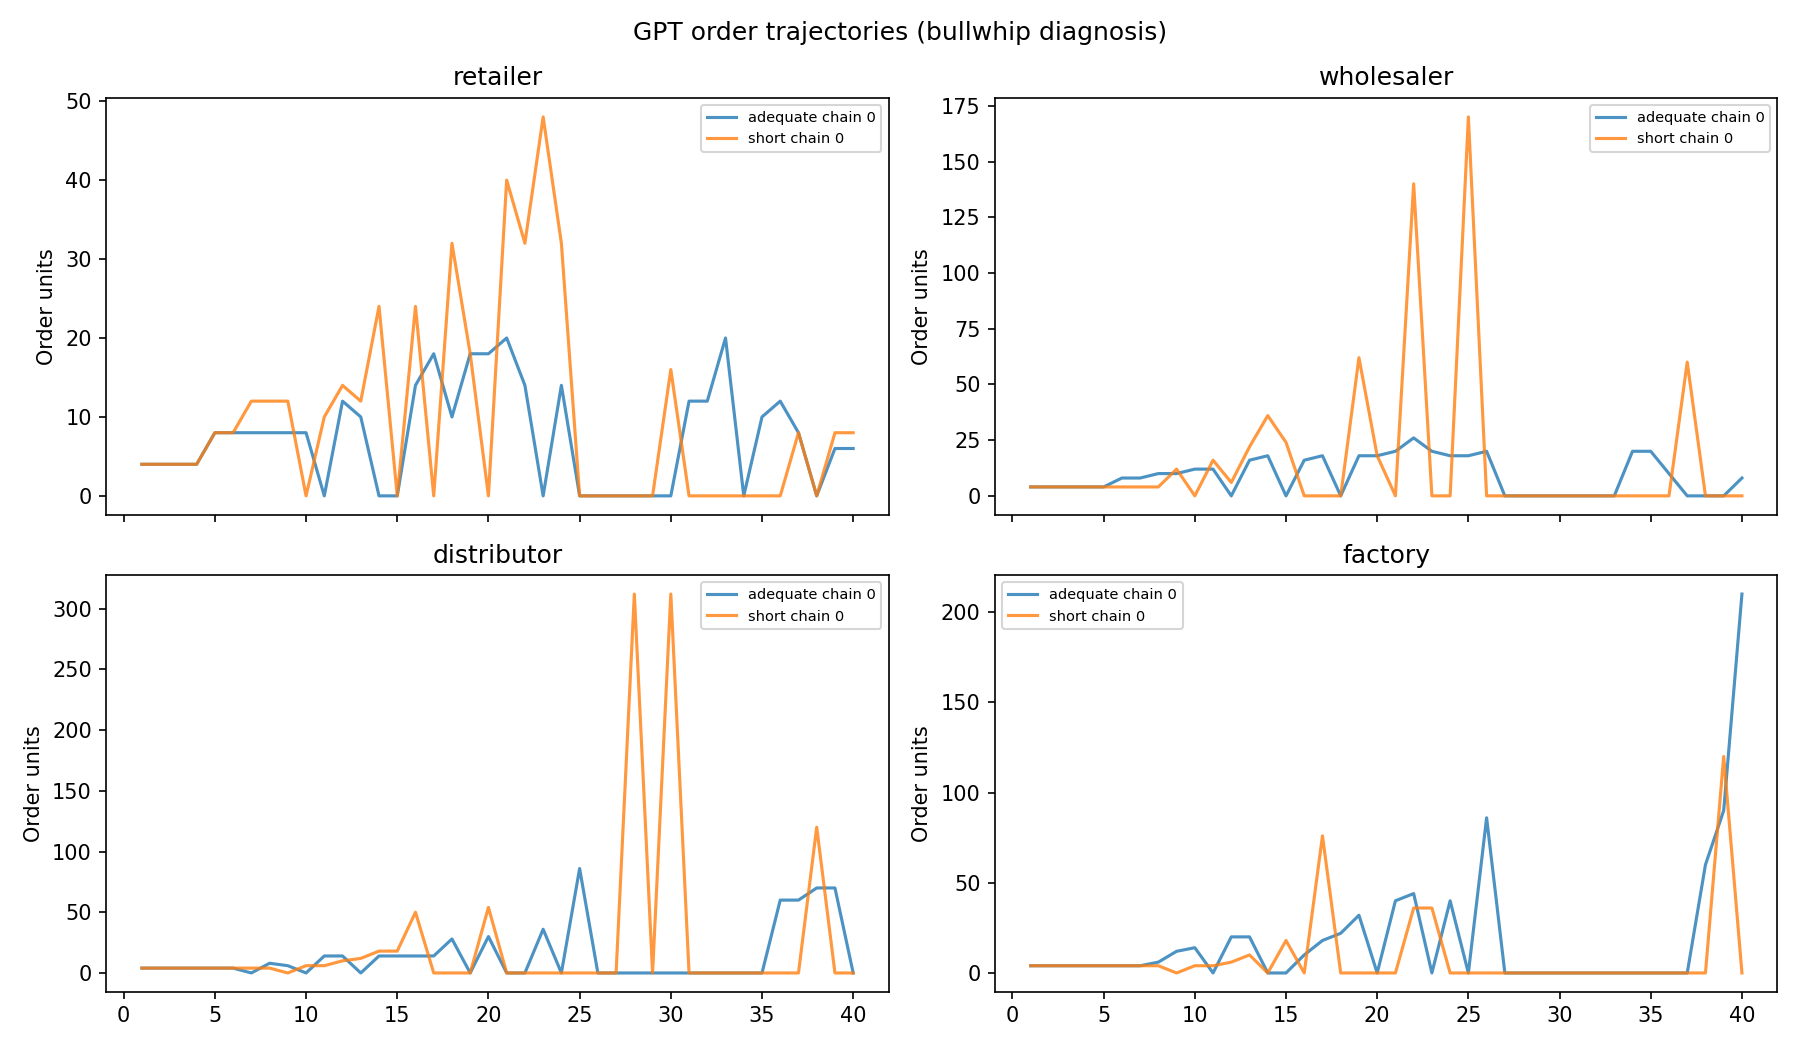

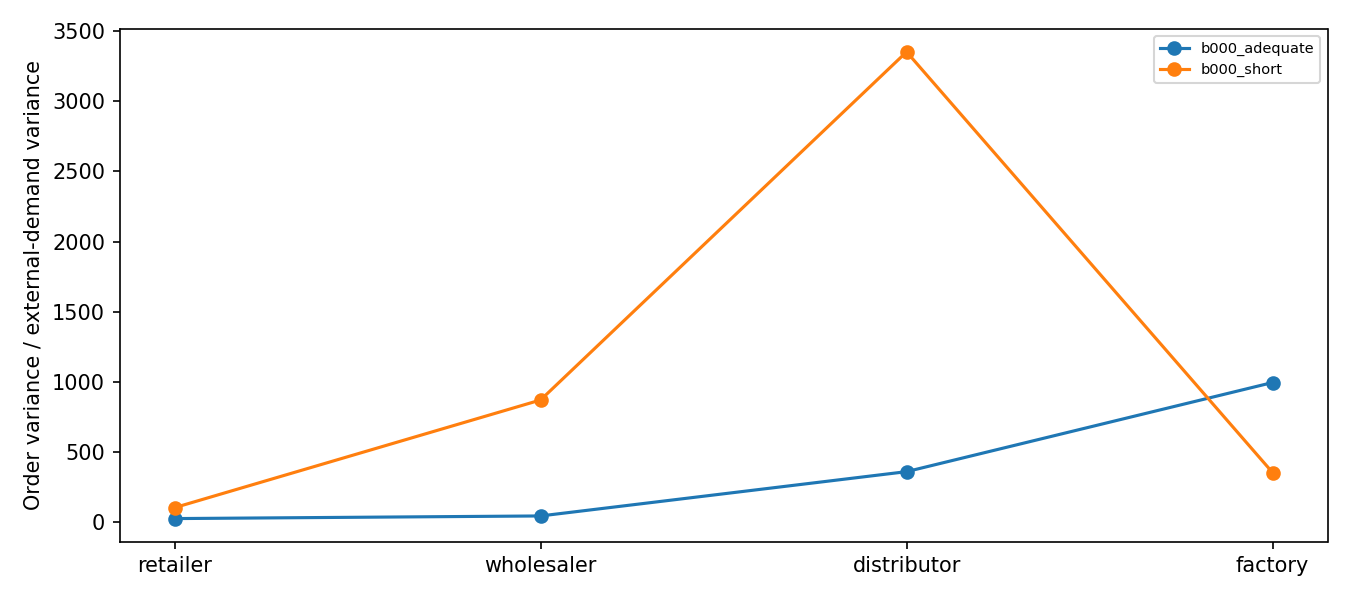

Word report: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/data/runs/game_api_8236a9c840b29d36/REPORT.docx
Detailed workbook: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/data/runs/game_api_8236a9c840b29d36/DETAILS.xlsx


In [6]:
# This cell only reads saved results and writes reports; no simulation/API calls.
# Works even if the kernel was started before the setup cell gained its dependency check.
import importlib.util, subprocess, sys
missing = [package for module, package in
           {"docx": "python-docx>=1,<2", "openpyxl": "openpyxl>=3,<4"}.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    importlib.invalidate_caches()

if (run_dir / "progress.json").exists():
    display(Markdown(report(run_dir)))
    for name in ("order_trajectories.png", "bullwhip.png"):
        if (run_dir / name).exists():
            display(Image(filename=str(run_dir / name)))
    print("Word report:", run_dir / "REPORT.docx")
    print("Detailed workbook:", run_dir / "DETAILS.xlsx")
    if (run_dir / "calibration_recommendation.json").exists():
        import json
        recommendation = json.loads((run_dir / "calibration_recommendation.json").read_text())
        print("Suggested settings (review before using):", recommendation)
        print("CALIBRATION_RUN =", repr(str(run_dir)))
else:
    print("No saved stage yet.")

## 6. What to do next

1. Run this entire notebook in **offline calibration** mode once.
2. Run **API calibration**; review whether the cap binds and the generous/doubled decisions are reasonably stable. A failed screen means the token contrast is not yet established; do not call it a successful time-pressure manipulation.
3. For a passed screen, copy its two budgets and folder into the settings, change `STAGE="game"`, and run **one group per condition** first. Keep `REPLICATE_ID` fixed to resume.
4. Assess beta identification, total costs, actual token use, failure rates and bullwhip patterns. Plan group-level replication/power before the proposed **10 groups per condition**. The previous $3 budget is not assumed sufficient for 80 agents.

No prompt, token budget or model guarantees realistic human behavior, bullwhip amplification or significant H1/H2. The study tests those outcomes.

The updated reflection also proposes explanations/questionnaires. Set `COLLECT_DEBRIEFS=True` **before a new game run** to save one concise retrospective self-report per agent. This is optional, adds API cost, and is separate from decision data. Model self-reports do not establish the actual mechanism behind decisions.

## 6. After this pilot

1. Reload this prepared notebook, restart the kernel, and run all cells. Enter the API key if requested. No calibration values or paths need to be entered.
2. When the game finishes, read the report and inspect total costs, beta identification, actual memo usage/truncation during full games, and bullwhip plots.
3. Keep the two-group run as a pilot. It is too small for hypothesis inference. Do not increase the sample to ten groups per condition until behavior, measurement, power and cost have been reviewed.
4. To resume an interrupted pilot, keep the same scientific settings and `REPLICATE_ID`; change only the local allowance if needed. Cached requests are reused.

No model or prompt guarantees realistic human behavior or significant H1/H2. The 240-versus-480 calibration comparison sat exactly at the pilot tolerance; continue to treat adequacy as provisional. Optional debriefs remain off to avoid extra calls. Select them before a separate new run if required.
